[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_paper_t2/BA_L5_paper_t2.ipynb)

# BA_L5_paper_t2: Distributional Accuracy of Depeg Forecasts (Published Table)

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Mean CRPS and mean threshold-weighted CRPS (twCRPS) of 24-hour distributional forecasts of the USDC/USDT deviation, January 2025 to May 2026: the proposed model against TimeXer, TiDE, GARCH, ARIMA and a naive forecast; values from Table 2 of Chaffard, Gaman, Staures, Ginavar, Jheng, Hardle and Pele (2026), Onchain Monitoring of Stablecoin Depeg Risk, working paper.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

Source: Table 2 of Chaffard, Găman, Staures, Ginavar, Jheng, Härdle & Pele (2026), *Onchain Monitoring of Stablecoin Depeg Risk*, working paper. The values are typed in below; nothing is estimated here.

The paper forecasts the full distribution of the USDC/USDT deviation 24 hours ahead with a monotone spline body, generalised Pareto (GPD) tails and the threshold-weighted continuous ranked probability score (twCRPS) as training loss.
It compares the model on the test period, January 2025 – May 2026, with five benchmarks: TimeXer and the Time-series Dense Encoder (TiDE), two neural forecasters; GARCH with Student-t errors (labelled GARCH in the chart); an autoregressive integrated moving average (ARIMA) model; and a naive forecast.
Left: the mean continuous ranked probability score (CRPS). Right: the mean twCRPS on a log scale. Lower is better.

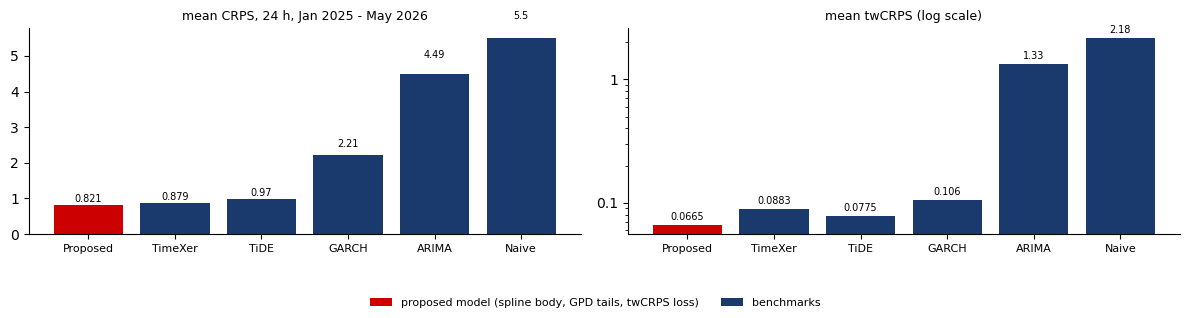

In [5]:
T2 = {'Proposed': (0.8205, 0.0665), 'TimeXer': (0.8787, 0.0883), 'TiDE': (0.9702, 0.0775), 'GARCH': (2.2140, 0.1060),
      'ARIMA': (4.4917, 1.3344), 'Naive': (5.4997, 2.1775)}            # (mean CRPS, mean twCRPS), 24-hour horizon, Table 2
nm = list(T2)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].bar(nm[:1], [T2[nm[0]][0]], color=RED, label='proposed model (spline body, GPD tails, twCRPS loss)')
ax[0].bar(nm[1:], [T2[k][0] for k in nm[1:]], color=BLUE, label='benchmarks')
ax[1].bar(nm, [T2[k][1] for k in nm], color=[RED] + [BLUE] * 5)
ax[0].set_title('mean CRPS, 24 h, Jan 2025 - May 2026', fontsize=9); ax[1].set_title('mean twCRPS (log scale)', fontsize=9)
ax[1].set_yscale('log'); ax[1].yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g'))
for a_, j in zip(ax, [0, 1]):
    a_.tick_params(axis='x', labelsize=8)
    for i, k in enumerate(nm):
        a_.text(i, T2[k][j] * 1.1, f'{T2[k][j]:.3g}', ha='center', fontsize=7)
save(fig, 'ba_l5_paper_t2', 0.14, ncol=2)

## Key numbers (Table 2 of the paper) and the reduction of the proposed model against each benchmark

In [6]:
tab = pd.DataFrame({k: {'mean CRPS': T2[k][0], 'mean twCRPS': T2[k][1],
                        'CRPS reduction of the proposed model (%)': 100 * (1 - T2['Proposed'][0] / T2[k][0]),
                        'twCRPS reduction of the proposed model (%)': 100 * (1 - T2['Proposed'][1] / T2[k][1])} for k in nm}).T
tab.loc['Proposed', ['CRPS reduction of the proposed model (%)', 'twCRPS reduction of the proposed model (%)']] = np.nan
tab.round(4)

,mean CRPS,mean twCRPS,CRPS reduction of the proposed model (%),twCRPS reduction of the proposed model (%)
Proposed,0.8205,0.0665,NaN,NaN
TimeXer,0.8787,0.0883,6.6234,24.6886
TiDE,0.9702,0.0775,15.4298,14.1935
GARCH,2.2140,0.1060,62.9404,37.2642
ARIMA,4.4917,1.3344,81.7330,95.0165
Naive,5.4997,2.1775,85.0810,96.9460


**How to read it:** the proposed model has the lowest loss on both scores; against the best benchmark the CRPS falls by 6.6% (TimeXer) and the twCRPS by 14.2% (TiDE).
Against GARCH-t the CRPS falls from 2.21 to 0.82 (63%) and the twCRPS from 0.106 to 0.067 (37%).